In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import Plot
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
import pandas as pd

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import matplotlib.lines as mlines
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
import matplotlib.colors as mcolors
from cartopy.mpl.patch import geos_to_path
import matplotlib.patches as mpatches 
from matplotlib.path import Path
import regionmask
import matplotlib as mpl

In [15]:
def add_graticule(ax, lat_labels=False, lon_labels=True):
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=0.6, color='gray', alpha=0.8, linestyle=':', zorder=20
    )
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 60))
    gl.ylocator = mticker.FixedLocator(np.arange(-60, 61, 30))
    gl.top_labels = gl.right_labels = False
    gl.bottom_labels = lon_labels
    gl.left_labels = lat_labels
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    gl.xpadding = 1.5 
    return gl

In [13]:
ds = xr.open_dataset("Figure3.nc")

cmap, levels, norm = Plot.def_colormap(max=2.0, interval=0.2, white=0.1, cmap='RdBu_r')
labels = [
    ['CMIP6', 'CMIP6-posIPO', 'CMIP6-negIPO',], 
    [None, 'CMIP6-posAMO', 'CMIP6-negAMO',], 
    ['EXT', 'EXT-posIPO', 'EXT-negIPO',], 
    [None, 'EXT-posAMO', 'EXT-negAMO',], 
]
numbers = [
    ['a', 'c', 'g'],
    [None,'d', 'h'],
    ['b', 'e', 'i'],
    [None,'f', 'j']
]
my_ds = [
    [ds['sst_CMIP6'], ds['sst_CMIP6_ipopos'], ds['sst_CMIP6_iponeg']], 
    [None, ds['sst_CMIP6_amopos'], ds['sst_CMIP6_amoneg']],
    [ds['sst_EXT'], ds['sst_EXT_ipopos'], ds['sst_EXT_iponeg']], 
    [None, ds['sst_EXT_amopos'], ds['sst_EXT_amoneg']],
]

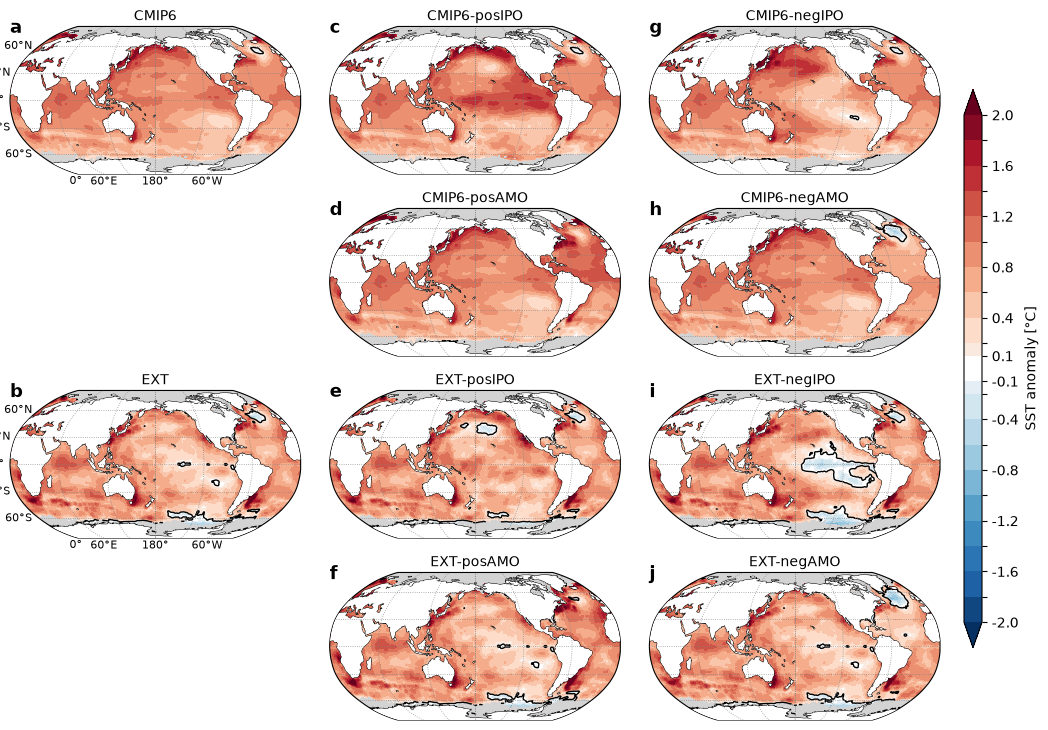

In [16]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(12, 9.3), 
                        subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})
plt.subplots_adjust(hspace=0.07, wspace=0.1)

for irow in range(4):
    for icol in range(3):
        ax = axs[irow,icol]
        if numbers[irow][icol] is None:
            ax.axis('off')
            continue
        ds_now = my_ds[irow][icol]
        p = ds_now.where(ds.icemask==0).plot.contourf(
            ax=ax, levels=levels, cmap=cmap, norm=norm, extend='both',
            add_colorbar=False, transform=ccrs.PlateCarree(), 
        )
        ds_now.where(ds.icemask==0).plot.contour(
            ax=ax, levels=[0], colors='black', linewidths=1.0, 
            transform=ccrs.PlateCarree(), add_colorbar=False, 
        )
        my_icemask = xr.where(ds.icemask==0, np.nan, 1.0)
        my_icemask.plot.contourf(
            ax=ax, transform=ccrs.PlateCarree(), levels=[0.5, 1.5], 
            colors=["lightgrey"], add_colorbar=False)
        ax.annotate(
            numbers[irow][icol], xy=(0, 1.05), xycoords='axes fraction',
            fontsize=13, fontweight='bold', ha='left', va='top'
        )
        ax.coastlines(linewidth=0.7)
        # ax.set_title(labels[irow][icol], fontsize=10)
        ax.text(0.5, 1.02, labels[irow][icol], transform=ax.transAxes, fontsize=10, ha='center', va='bottom')
        ax.add_feature(cfeature.LAND, facecolor="white", zorder=10)
        add_graticule(ax, lat_labels=(icol==0), lon_labels=(icol==0))

cax = fig.add_axes([0.92, 0.2, 0.015, 0.6])  # [left, bottom, width, height] in figure coords

cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap, norm=norm),
                    cax=cax, orientation='vertical', ticks=levels[levels != 0], 
                    extend='both', spacing='proportional')
major_ticks = [-2.0, -1.6, -1.2, -0.8, -0.4, -0.1, 0.1, 0.4, 0.8, 1.2, 1.6, 2.0]
major_labels = [ '' if t not in major_ticks else f'{t:.1f}' for t in levels[levels != 0]]
cbar.ax.minorticks_off()
cbar.ax.set_yticklabels(major_labels, minor=False)
cbar.set_label('SST anomaly [°C]')
# plt.savefig(f"Figure3.png", dpi=300, bbox_inches='tight', pad_inches=0.25)